# Monitoreo de ganado con collar: proyecto completo con MmCows
**Visualización de Datos 2026B · Rafael Said De la Paz Coronado · TecNM / Instituto Tecnológico de Aguascalientes**

Este notebook reúne todo el proyecto en el orden en que se hace el análisis:

| Sección | Qué hace | Avance |
|---|---|---|
| 1. Configuración | Librerías y ubicación de los datos | — |
| 2. Carga | Lee los CSV originales sin modificarlos | 2 |
| 3. Limpieza | Revisa la calidad de los datos y documenta cada decisión | 2 |
| 4. Tablas derivadas | Agrega por hora y por vaca-día | 2 |
| 5. EDA | Las 6 visualizaciones exploratorias | 2 |
| 6. Visualizaciones finales | Estática mejorada, interactiva y tablas para BI | 3 |
| 7. Resumen | Cifras clave y versiones usadas | 3 |

**Pregunta del proyecto:** ¿cómo responden la temperatura corporal y el tiempo echada de cada vaca al estrés calórico del corral, qué tan distinto es el patrón normal de cada una, y puede un collar (sin sensor en la pata) capturar esas señales?

**Datos:** MmCows (Vu et al., 2024), <https://huggingface.co/datasets/neis-lab/mmcows>. Ver `datos/README.md` para descargarlos; no se incluyen en el repositorio por la licencia.

La lógica vive en `src/` (funciones con comentarios) y este notebook la va llamando y explicando. Así el mismo código sirve para el notebook y para `ejecutar_todo.py`, y no hay dos versiones de la limpieza.

## 1. Configuración

**Si lo corres en Google Colab:** ejecuta primero esta celda descomentando las líneas. Clona el repositorio y monta tu Drive, donde debes tener la carpeta `mmcows/main_data` con las cuatro subcarpetas que indica `datos/README.md`.

In [1]:
# --- Solo en Google Colab ---
# !git clone https://github.com/USUARIO/proyecto_mmcows.git
# %cd proyecto_mmcows/notebooks
# from google.colab import drive; drive.mount('/content/drive')
# import os; os.environ["MMCOWS_DATA"] = "/content/drive/MyDrive/mmcows"

In [2]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# El notebook vive en notebooks/; el código en src/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import datos, eda_avance2, avance3
print("Datos en:", datos.ruta_datos())

Datos en: /sessions/rcw-01kkjtvupzow1rewel44tyss/mnt/sensor_data


## 2. Carga de datos
`cargar_crudos()` lee los archivos tal como vienen del dataset. Lo único que agrega es la columna `cow` para saber de qué vaca es cada fila. La ubicación (UWB) usa los nombres T01–T10 para las mismas vacas C01–C10, así que aquí se unifican.

In [3]:
crudos = datos.cargar_crudos()
for nombre, df in crudos.items():
    print(f"{nombre:6s} {df.shape[0]:>9,} filas × {df.shape[1]} columnas   columnas: {list(df.columns)}")

cbt      197,920 filas × 3 columnas   columnas: ['timestamp', 'temperature_C', 'cow']
thi       19,831 filas × 4 columnas   columnas: ['timestamp', 'temperature_F', 'humidity_per', 'THI']
ankle    197,920 filas × 4 columnas   columnas: ['timestamp', 'datetime', 'lying', 'cow']
uwb      788,608 filas × 5 columnas   columnas: ['timestamp', 'coord_x_cm', 'coord_y_cm', 'coord_z_cm', 'cow']


### Primera mirada
`.describe()` es la forma más rápida de detectar valores raros. Fíjate en el **mínimo de la temperatura corporal**: una vaca viva no puede estar a 21.9 °C.

In [4]:
crudos["cbt"].temperature_C.describe().round(2)

count    197920.00
mean         38.49
std           0.28
min          21.90
25%          38.31
50%          38.47
75%          38.66
max          39.51
Name: temperature_C, dtype: float64

In [5]:
# Y en el THI: la columna se llama temperature_F, pero sus valores solo tienen sentido en °C
crudos["thi"][["temperature_F", "humidity_per", "THI"]].describe().round(1)

,temperature_F,humidity_per,THI
count,19831.0,19831.0,19831.0
mean,23.2,77.5,71.6
std,3.7,12.1,5.3
min,14.4,46.3,58.0
25%,20.5,67.8,68.1
50%,23.0,79.7,71.8
75%,26.1,87.9,75.4
max,31.7,97.3,83.1


## 3. Limpieza
Antes de quitar algo, primero lo **muestro**. Estas son las lecturas imposibles:

In [6]:
cbt = crudos["cbt"].assign(t=datos.a_hora_local(crudos["cbt"].timestamp))
cbt[cbt.temperature_C < datos.TEMP_MINIMA_VIVA][["cow", "t", "temperature_C"]]

,cow,t,temperature_C
163708,C09,2023-07-25 07:20:00,27.21
163709,C09,2023-07-25 07:21:00,23.51
163710,C09,2023-07-25 07:22:00,21.90
163711,C09,2023-07-25 07:23:00,22.93
163712,C09,2023-07-25 07:24:00,24.33
163713,C09,2023-07-25 07:25:00,29.11
163714,C09,2023-07-25 07:26:00,32.96
163715,C09,2023-07-25 07:27:00,35.06
163716,C09,2023-07-25 07:28:00,36.23
163717,C09,2023-07-25 07:29:00,36.87


Son 10 minutos seguidos de la misma vaca (C09, 25/07 de 7:20 a 7:29). Eso indica una falla del registrador, no un evento de salud: la temperatura de una vaca no puede caer más de 16 °C y regresar a la normal en 10 minutos. Las excluyo con un **criterio físico** (< 37 °C), no porque estorben en la gráfica.

`limpiar()` aplica todas las decisiones y devuelve un **reporte**. Ese reporte es la documentación de la limpieza: si alguien repite el análisis, ve qué se quitó y por qué.

In [7]:
L, reporte = datos.limpiar(crudos)
reporte

,problema,filas_afectadas,decision
0,Tiempo en formato Unix (UTC),todas,Convertir a hora local CDT (UTC−5)
1,10 lecturas < 37 °C de C09 (25/07 07:20–07:29)...,10,Excluir: falla del sensor
2,Columna temperature_F con valores en °C (14–32),0,Renombrar a temperatura_aire_C
3,"Días incompletos: 21/07, 04/08",10720,Para totales diarios usar solo los 13 días com...
4,Lecturas UWB vacías (4.9 %),39024,Descartar esas filas


In [8]:
print("Lecturas de temperatura después de limpiar:", f"{len(L['cbt']):,}")
print("Días completos:", L["dias_completos"][0], "a", L["dias_completos"][-1], f"({len(L['dias_completos'])} días)")

Lecturas de temperatura después de limpiar: 197,910
Días completos: 2023-07-22 a 2023-08-03 (13 días)


## 4. Tablas derivadas
Las gráficas no usan los datos minuto a minuto, sino agregados:
- **por hora:** temperatura de cada vaca (con promedio móvil de 3 h para quitar el ruido) y THI del corral con su nivel de estrés;
- **por vaca y día:** horas echada (solo días completos) y cuánto se aleja cada día del promedio de esa misma vaca (desviaciones estándar).

In [9]:
T = datos.tablas_derivadas(L)
for nombre, df in T.items():
    print(f"{nombre:10s} {len(df):>6,} filas")
T["echada"].head()

temp_hora   3,313 filas
thi_hora      332 filas
echada        130 filas
temp_dia      150 filas
thi_dia        15 filas


,cow,d,horas_echada,z,dia_atipico
0,C01,2023-07-22,13.433333,-1.284312,False
1,C01,2023-07-23,15.150000,0.390171,False
2,C01,2023-07-24,14.166667,-0.568999,False
3,C01,2023-07-25,15.366667,0.601513,False
4,C01,2023-07-26,14.900000,0.146314,False


## 5. Análisis exploratorio (Avance 2)
Las 6 figuras del Avance 2, generadas con el mismo código de ese entregable. La regla de color es la misma en todo el proyecto: **gris** para el contexto, **azul** para lo normal y **naranja** solo para lo que pide atención.

In [10]:
cifras = eda_avance2.generar(L, RAIZ / "figuras" / "avance2")

**Fig. 1 · Univariada.** Histograma de la temperatura corporal. El 90 % está entre 38.08 y 38.96 °C y solo el 0.66 % rebasa 39.2 °C: la señal útil está en décimas de grado.

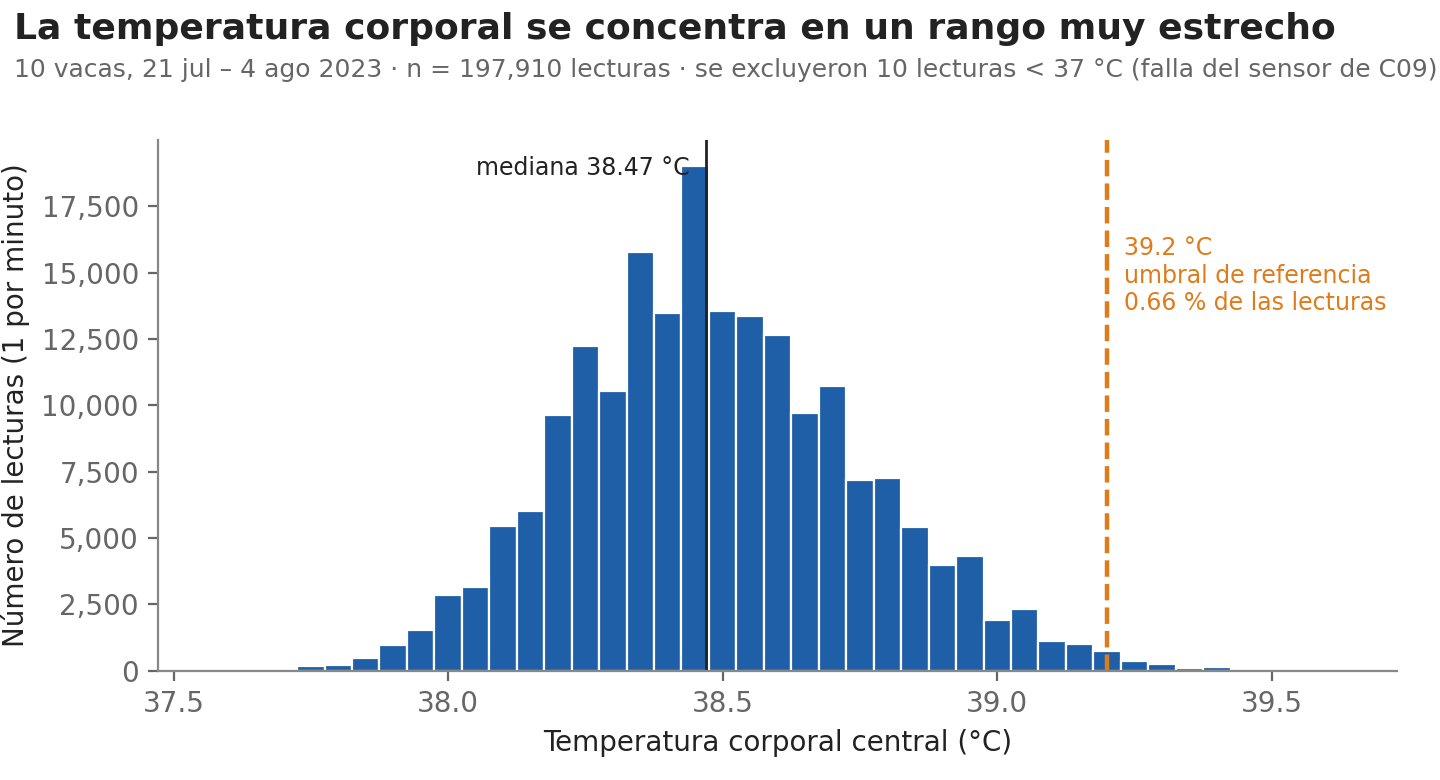

In [11]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig1_univariada.png"), width=720))

**Fig. 2 · Bivariada.** THI del día contra horas echada. La relación es negativa y moderada (r = −0.29): unas 2.1 h menos echada por cada 10 puntos de THI.

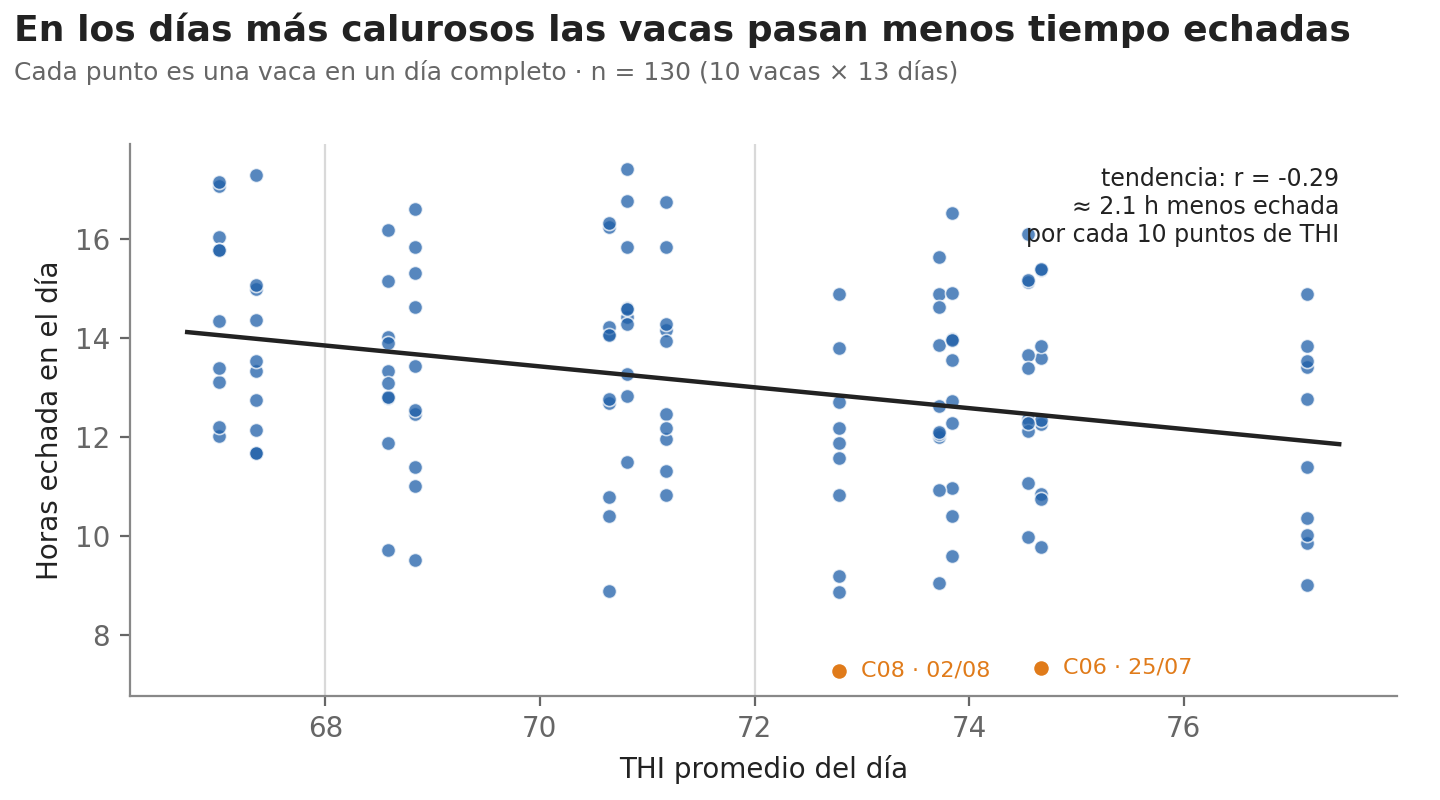

In [12]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig2_bivariada.png"), width=720))

**Fig. 3 · Multivariada.** Ciclo diario. El THI llega a su máximo a las 16:00 y la temperatura corporal a las 18:00, unas 2 h después.

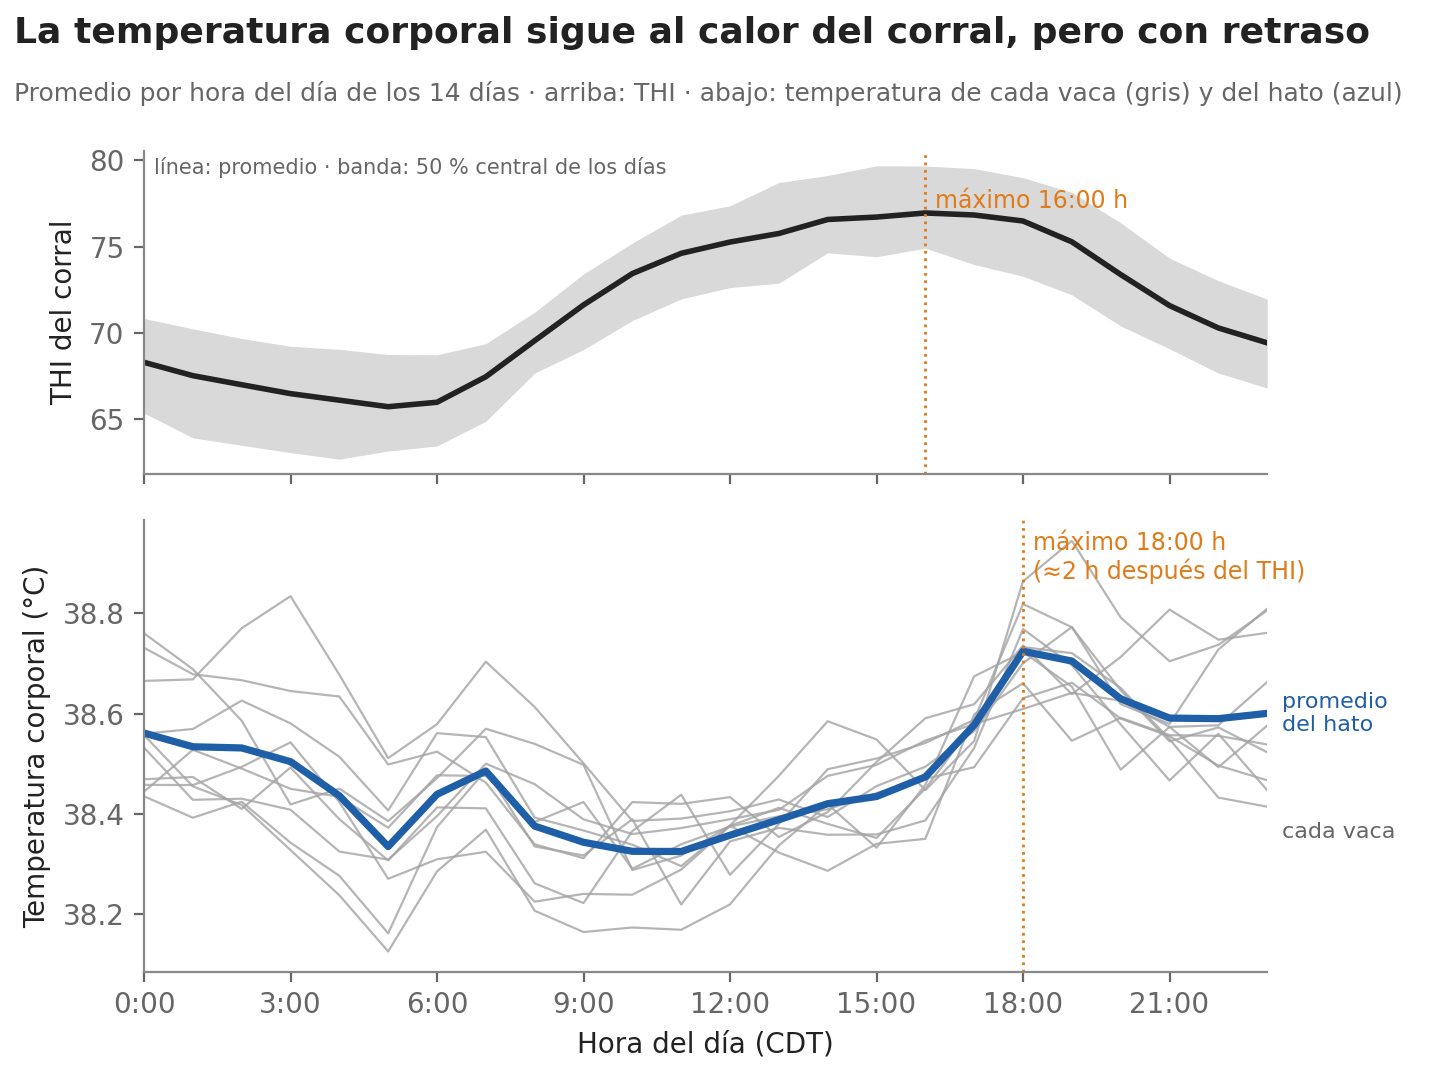

In [13]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig3_multivariada.png"), width=720))

**Fig. 4 · Temporal.** C09 contra el rango de las otras 9 vacas. Es la figura que se lleva a versión final en la sección 6.

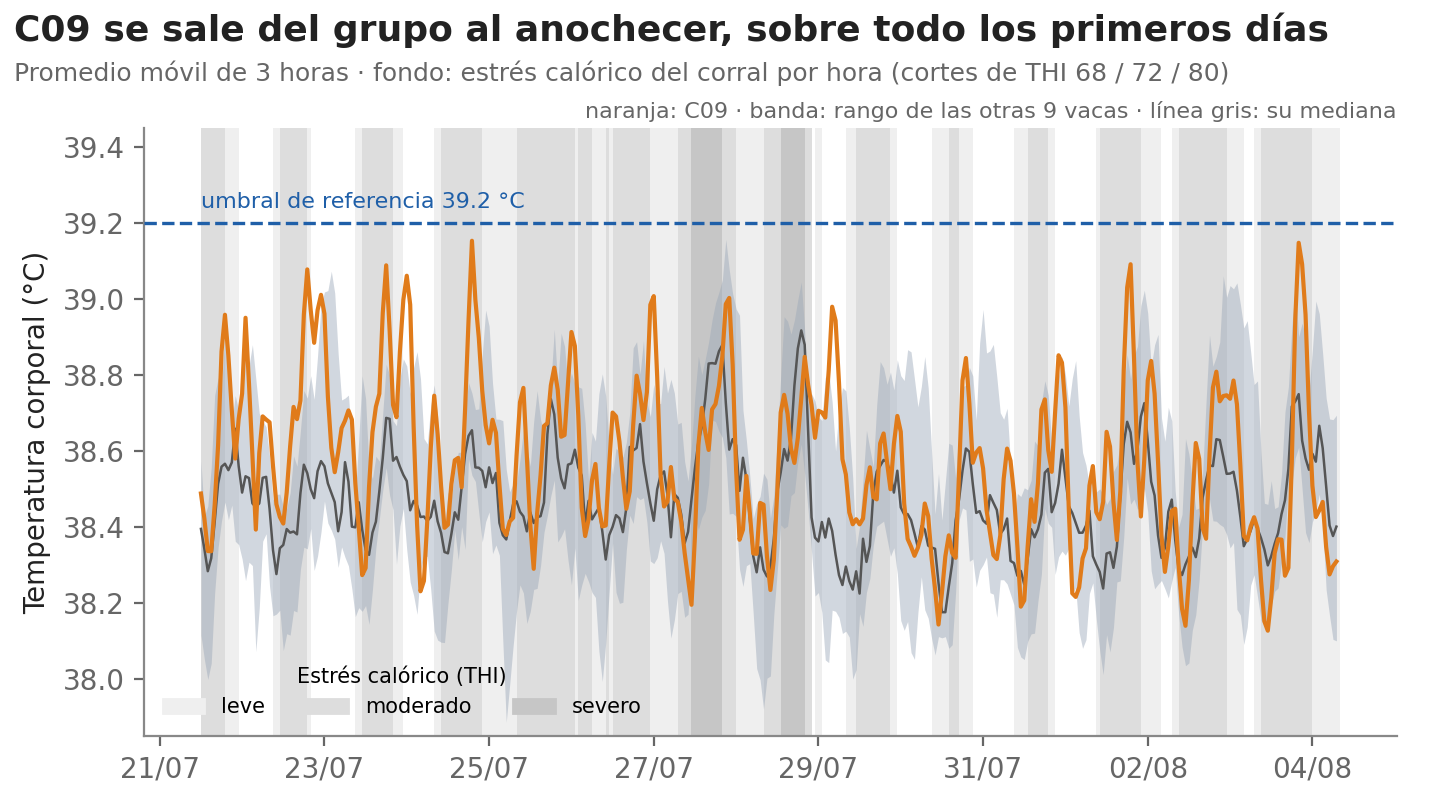

In [14]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig4_temporal.png"), width=720))

**Fig. 5 · Comparación de grupos.** Horas echada por vaca: de 10.0 h (C06) a 16.3 h (C07). No sirve un solo umbral para todas.

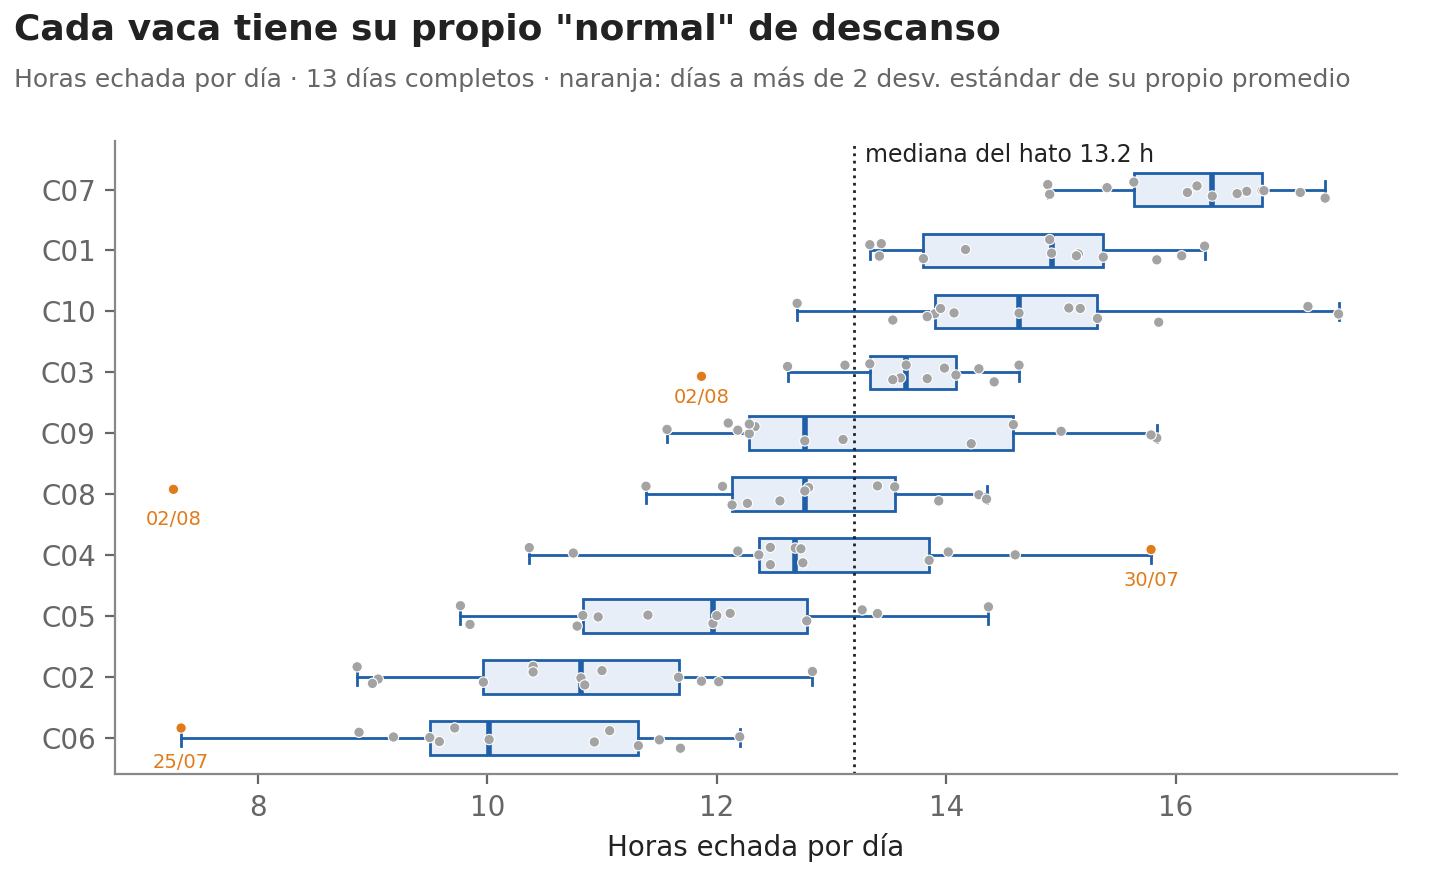

In [15]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig5_grupos.png"), width=720))

**Fig. 6 · Adicional.** La altura del collar (UWB) distingue si la vaca está echada en el 85.7 % de los minutos con un corte en 105 cm.

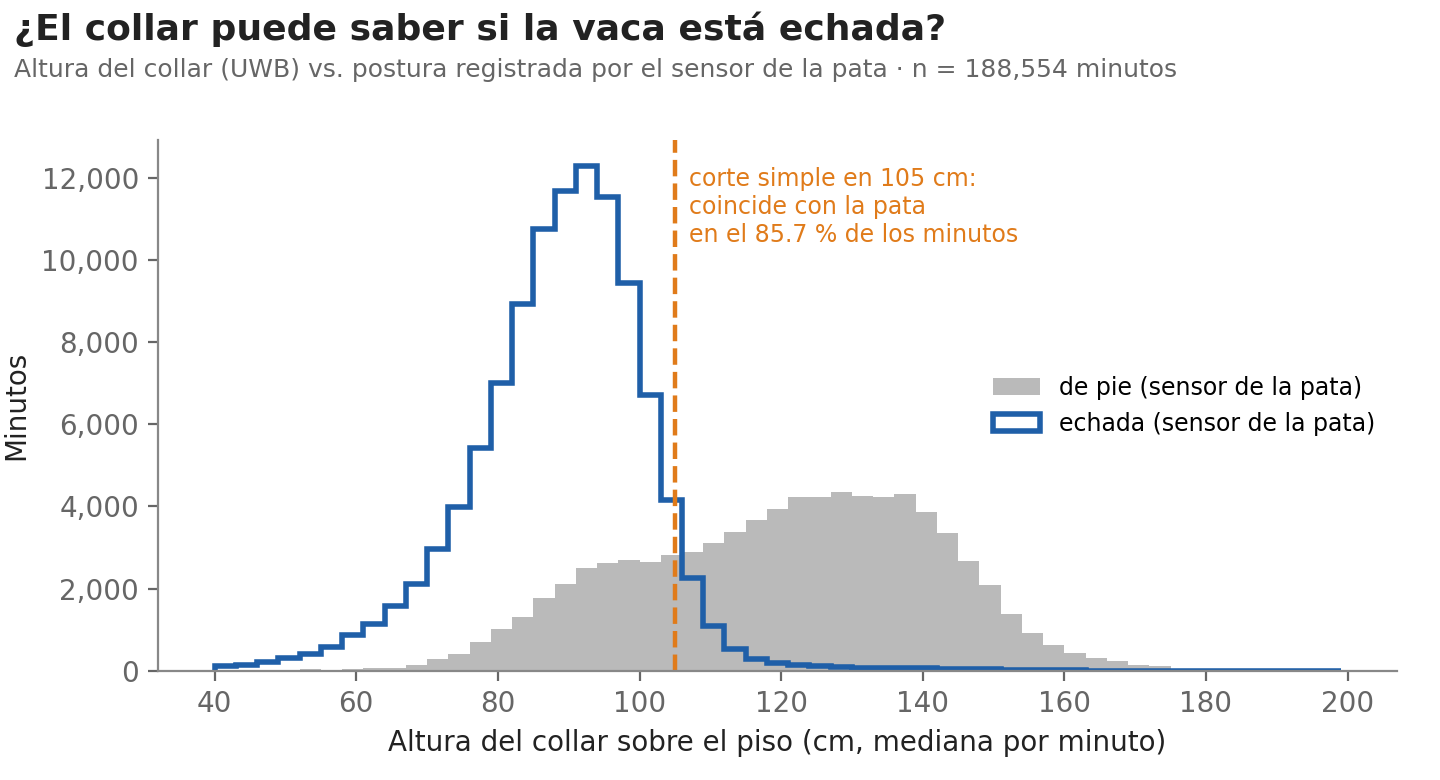

In [16]:
display(Image(filename=str(RAIZ / "figuras" / "avance2" / "fig6_collar.png"), width=720))

## 6. Visualizaciones finales (Avance 3)
### 6.1 Estática final (matplotlib)
Es la Fig. 4 mejorada. Cambios respecto al Avance 2:
- El estrés calórico sale del fondo y pasa a una franja propia abajo. Antes, las bandas grises del fondo competían con la banda gris de las vacas (problema de figura-fondo).
- Agregué anotaciones con el hallazgo dentro de la gráfica: el pico del 24/07 a las 19:00, el 77 % de los minutos altos entre las 18:00 y las 20:00, y el 74 % en los primeros 4 días. También marqué que el 27/07, el día más caluroso, solo sumó 10 minutos.
- Puse etiquetas directas al final de las líneas en lugar de un texto-leyenda arriba.
- El título dice el hallazgo, no el tipo de gráfica.

{'vaca': 'C09', 'min_sobre': 517, 'pct_18_20': np.float64(76.8), 'pct_primeros4': np.float64(73.7), 'dia_caluroso': '2023-07-27', 'thi_dia_caluroso': np.float64(77.1), 'min_dia_caluroso': 10, 'pico': ['24/07 19:00', np.float64(39.15)]}


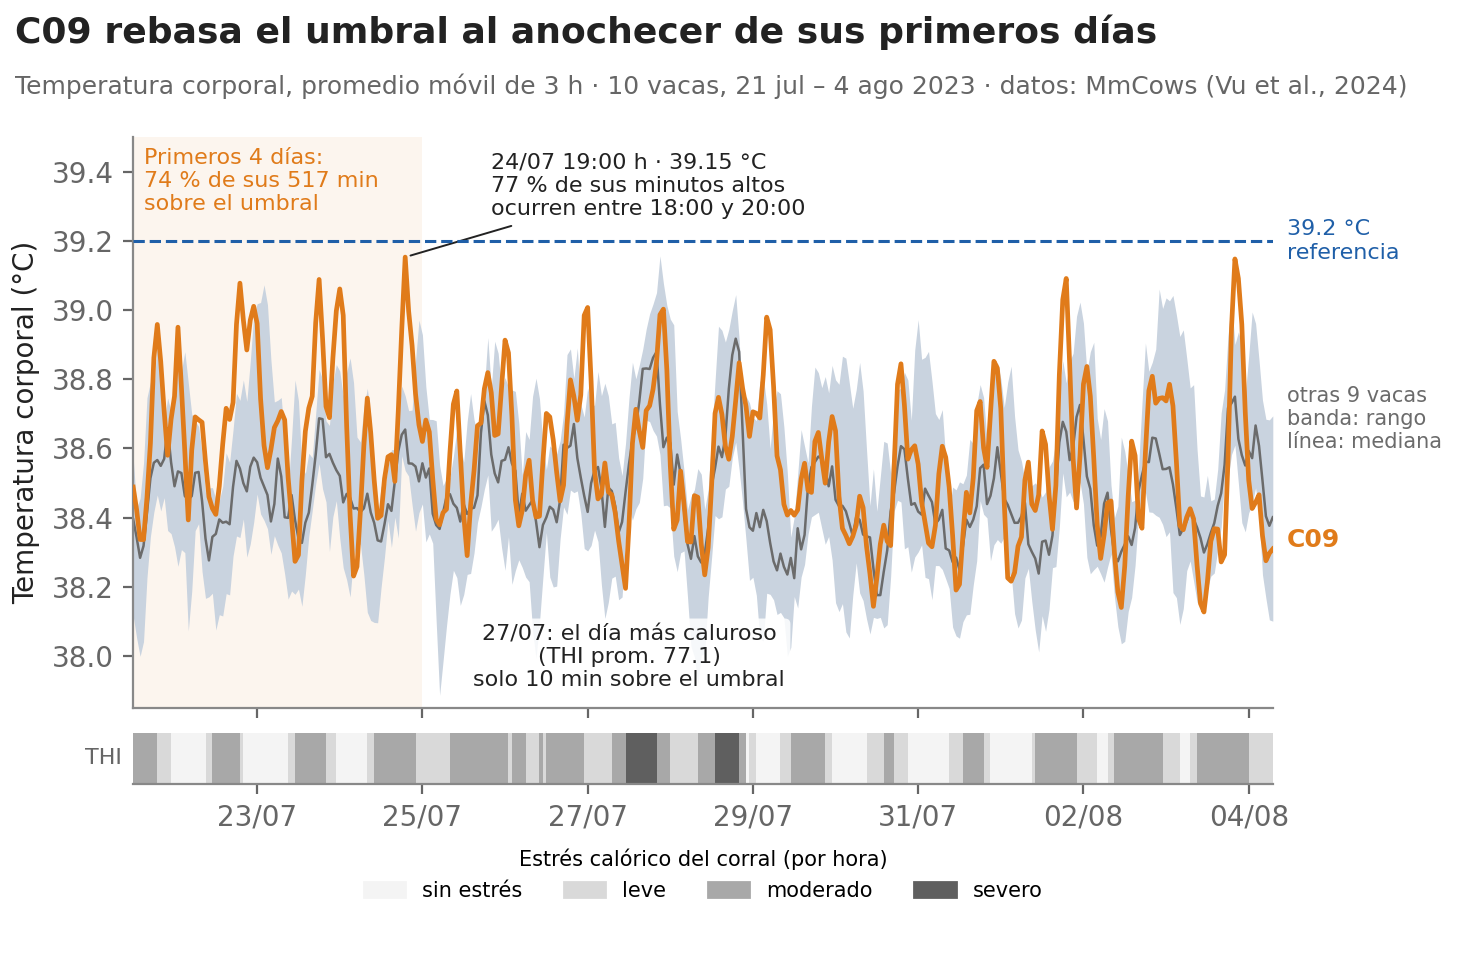

In [17]:
res = avance3.estatica_fig4(L, T, RAIZ / "figuras" / "avance3" / "fig4_estatica_final.png")
print(res)
display(Image(filename=str(RAIZ / "figuras" / "avance3" / "fig4_estatica_final.png"), width=760))

### 6.2 Interactiva (Plotly)
La misma pregunta, pero para **cualquier vaca**:
- **Menú "Vaca a revisar"** (selección dinámica): cambia la vaca resaltada contra el rango de las otras 9.
- **Detalle al pasar el cursor** (hover): temperatura, diferencia contra la mediana del grupo y THI con su nivel de estrés en esa hora.
- **Zoom:** botones de 1 día, 3 días o todo el periodo, y arrastre con el mouse.

Se guarda como `figuras/avance3/fig4_interactiva.html`, que se abre con doble clic en cualquier navegador con internet. En Jupyter, VS Code o Colab también se ve aquí abajo. GitHub no muestra gráficas interactivas en la vista previa del notebook; para eso está el HTML.

In [18]:
fig = avance3.interactiva_fig4(L, T, RAIZ / "figuras" / "avance3" / "fig4_interactiva.html")
fig

### 6.3 Tablas para el componente de BI (Tableau Public)
Tableau trabaja mejor con una tabla "plana", con una fila por observación y columnas con nombres claros. `exportar_bi()` genera dos:
- `bi/vaca_dia.csv`: una fila por vaca y día (150 filas). Sirve para las tarjetas KPI, el mapa de calor y el descanso por vaca.
- `bi/vaca_hora.csv`: una fila por vaca y hora, para una serie de tiempo.

La construcción del dashboard está documentada paso a paso en `bi/GUIA_TABLEAU.md`. Los KPIs de abajo son los valores que debe mostrar el tablero, y sirven para comprobar que quedó bien.

In [19]:
kpi = avance3.exportar_bi(L, T, RAIZ / "bi")
print(kpi)
pd.read_csv(RAIZ / "bi" / "vaca_dia.csv").head()

{'temp_mediana': np.float64(38.47), 'pct_minutos_sobre_umbral': np.float64(0.66), 'horas_echada_mediana': np.float64(13.2), 'dias_atipicos': 4, 'filas_vaca_dia': 150, 'filas_vaca_hora': 3313}


,vaca,fecha,dia_completo,horas_echada,desv_estandar_echada,dia_atipico,temp_promedio,temp_maxima,minutos_sobre_umbral,minutos_registrados,thi_promedio,thi_maximo
0,C01,2023-07-21,No,NaN,NaN,Sin dato,38.496,38.82,0,690,71.445,73.76
1,C01,2023-07-22,Sí,13.433,-1.284,No,38.436,38.95,0,1440,68.841,75.88
2,C01,2023-07-23,Sí,15.150,0.390,No,38.504,38.82,0,1440,68.588,75.85
3,C01,2023-07-24,Sí,14.167,-0.569,No,38.416,38.79,0,1440,71.179,76.97
4,C01,2023-07-25,Sí,15.367,0.602,No,38.483,39.07,0,1440,74.670,80.16


## 7. Resumen y reproducibilidad

In [20]:
cifras_todas = {"avance2": cifras, "avance3_estatica": res, "bi": kpi}
(RAIZ / "salidas").mkdir(exist_ok=True)
(RAIZ / "salidas" / "cifras.json").write_text(json.dumps(cifras_todas, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
reporte.to_csv(RAIZ / "salidas" / "reporte_limpieza.csv", index=False, encoding="utf-8-sig")

import platform, numpy, matplotlib, plotly
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", numpy.__version__,
      "| matplotlib", matplotlib.__version__, "| plotly", plotly.__version__)

Python 3.10.12 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.9 | plotly 7.1.0


**Para repetir el análisis:** con los datos en `datos/mmcows/main_data/` (o en la ruta de `MMCOWS_DATA`), ejecuta *Kernel → Restart & Run All*, o desde la terminal `python ejecutar_todo.py`. Las cifras de `salidas/cifras.json` deben coincidir con las de los documentos de cada avance.

**Referencia:** Vu, H., Prabhune, O. C., Raskar, U., Panditharatne, D., Chung, H., Choi, C., & Kim, Y. (2024). MmCows: A multimodal dataset for dairy cattle monitoring. *Advances in Neural Information Processing Systems, 37*, 59451–59467.